# Session 02 · Part 2 — Complete the agent: persistence, streaming, human-in-the-loop

Starting from the loop of Part 1, you finish the **Research Brief Agent**:

<img src="images/research_brief_agent.png" width="720">

`research_agent` is the loop of Part 1, compiled as a graph and added as **one node** of the outer graph
([subgraphs](https://docs.langchain.com/oss/python/langgraph/use-subgraphs)). The outer graph keeps the business steps.

1. **Persistence**: a checkpointer saves the state per `thread_id`, so a run can pause and continue, even after a restart.
2. **Streaming**: see each step while it runs.
3. **Human-in-the-loop**: the agent asks when the request is unclear (`ask_user`) and waits for approval before writing a file.
4. **Loop control**: retry transient errors; `recursion_limit` bounds every run.

As in Part 1, the hand-built graph is here to show how such an agent works inside; later sessions use `create_agent`
and Deep Agents, which work the same way (section 7 rebuilds this agent with `create_agent`).

The outputs below come from a real run. Section 6 lists the scenarios it covers.

References: [Checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers) ·
[Streaming](https://docs.langchain.com/oss/python/langgraph/streaming) ·
[Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts) ·
[Human-in-the-loop middleware](https://docs.langchain.com/oss/python/langchain/human-in-the-loop) ·
[Fault tolerance](https://docs.langchain.com/oss/python/langgraph/fault-tolerance)

## 0. Setup: model and tools from Part 1

In [32]:
import logging
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
for noisy in ("httpx", "httpx2"):  # HTTP clients log every request at INFO
    logging.getLogger(noisy).setLevel(logging.WARNING)
logger = logging.getLogger(__name__)

# ── Keys and model (.env of this session folder) ─────────────────────────────
load_dotenv()
for name in ("OPENAI_API_KEY", "TAVILY_API_KEY"):
    if not os.getenv(name, "").strip():
        raise RuntimeError(f"Missing {name}: copy .env.example to .env in the session folder and fill it in")

model = init_chat_model(os.getenv("MODEL", "openai:gpt-6-luna"))
logger.info("Model: %s", model.model_name)

INFO | Model: gpt-6-luna


In [33]:
# ── Tools: web search and page reading with Tavily ───────────────────────────
from langchain.tools import tool
from tavily import BadRequestError, TavilyClient

tavily = TavilyClient()  # uses TAVILY_API_KEY


@tool
def search_docs(query: str) -> list[dict]:
    """Search the web for documents about the query. Returns the title and url of the top 3 results."""
    hits = tavily.search(query, max_results=3)["results"]
    return [{"title": h["title"], "url": h["url"]} for h in hits]


@tool
def read_doc(url: str, question: str) -> str:
    """Read the parts of one document (a web page from search_docs) that answer the question."""
    try:
        pages = tavily.extract(urls=[url], query=question, chunks_per_source=3)["results"]
    except BadRequestError as error:  # bad input: tell the model so it can pick another page
        return f"ERROR: could not read {url} ({error})"
    return pages[0]["raw_content"] if pages else f"ERROR: could not read {url}"

In [34]:
SYSTEM_PROMPT = (
    "You write short research briefs (under 250 words) from sources you read with the tools only. "
    "Call independent tools together in one turn (several searches, or several pages to read), "
    "and read two or three different pages before writing; prefer official or primary sources. "
    "Cite every point with the url you read. If the sources do not answer, say so; never invent facts or urls. "
    "End with the brief itself, no follow-up offers."
)

## 1. `ask_user`: a tool that pauses the graph

The model sees `ask_user` like any other tool and **decides itself** to call it. Inside the tool, `interrupt()` stops the
graph and the checkpointer saves the state. The answer you send back with `Command(resume=...)` becomes the return value of
`interrupt()`, so it reaches the model as a normal `ToolMessage`.

In [35]:
from langgraph.types import interrupt


@tool
def ask_user(question: str) -> str:
    """Ask the user a question when the request is unclear or misses details you need. Returns the user's answer."""
    return interrupt({"type": "question", "question": question})


tools = [search_docs, read_doc, ask_user]
tools_by_name = {t.name: t for t in tools}
model_with_tools = model.bind_tools(tools)
GRAPH_PROMPT = SYSTEM_PROMPT + (
    " Before searching, check the request: if the topic, scope or intended reader is unclear or missing,"
    " call the ask_user tool once with one short question that covers what you need."
    " If the request is already clear, do not ask. Never ask questions in a normal reply: use ask_user."
)

## 2. The research loop: `research_agent`

The loop of Part 1 with three changes:
- the state is `MessagesState` (its `add_messages` reducer merges messages by id: when the subgraph hands its messages back
  to the outer graph, nothing is duplicated);
- tool calls fan out with `Send` as in Part 1; each `tool_node` task sends a progress event with `get_stream_writer()`
  (section 5) and retries transient errors (`RetryPolicy`, per task);
- the tools include `ask_user`.

In [36]:
from pathlib import Path
from typing import Literal
from langchain.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.runnables import RunnableConfig
from langgraph.config import get_stream_writer
from langgraph.graph import MessagesState, StateGraph, START, END
from langgraph.types import Command, RetryPolicy, Send


class AgentState(MessagesState):
    approval: str
    output_path: str


def llm_call(state: AgentState) -> dict:
    response = model_with_tools.invoke([SystemMessage(GRAPH_PROMPT)] + state["messages"])
    return {"messages": [response]}


def tool_node(tool_call: dict) -> dict:
    """Run ONE tool call (the Send payload); calls of the same model turn run in parallel."""
    get_stream_writer()({"status": f"{tool_call['name']} {tool_call['args']}"})
    observation = tools_by_name[tool_call["name"]].invoke(tool_call["args"])
    return {"messages": [ToolMessage(content=str(observation), tool_call_id=tool_call["id"])]}


def should_continue(state: AgentState) -> list[Send] | Literal["__end__"]:
    tool_calls = state["messages"][-1].tool_calls
    if not tool_calls:
        return END
    return [Send("tool_node", call) for call in tool_calls]


research = StateGraph(AgentState)
research.add_node("llm_call", llm_call)
research.add_node("tool_node", tool_node, retry_policy=RetryPolicy(max_attempts=3))
research.add_edge(START, "llm_call")
research.add_conditional_edges("llm_call", should_continue, ["tool_node", END])
research.add_edge("tool_node", "llm_call")
research_agent = research.compile()  # no checkpointer here: it uses the outer graph's

## 3. The outer graph: review, then save

- `review_brief` only **asks** (interrupt) and returns a `Command` to pick the next node:
  approve / edit → `save_brief`, reject → back to `research_agent` with the feedback.
- `save_brief` is a separate node that **writes** the file. Resume re-runs the whole node that called `interrupt()`;
  because the write happens in another node, the file is written once, and only after approval.
- Citations come from `read_sources()`: the urls `read_doc` really read, as in Part 1.

In [37]:
OUTPUT_DIR = Path("output")

def read_sources(messages: list) -> list[str]:
    """Urls of read_doc calls that returned content (not the urls the model writes in its answer)."""
    ok = {m.tool_call_id for m in messages if isinstance(m, ToolMessage) and not m.text.startswith("ERROR")}
    return sorted({
        call["args"]["url"]
        for m in messages if isinstance(m, AIMessage)
        for call in m.tool_calls if call["name"] == "read_doc" and call["id"] in ok
    })


def review_brief(state: AgentState) -> Command[Literal["save_brief", "research_agent"]]:
    decision = interrupt({
        "type": "review",
        "action": "save_brief",
        "draft": state["messages"][-1].text,
        "citations": read_sources(state["messages"]),
    })
    if decision["type"] == "approve":
        return Command(update={"approval": "approved"}, goto="save_brief")
    if decision["type"] == "edit":
        return Command(update={"approval": "edited", "messages": [AIMessage(decision["draft"])]}, goto="save_brief")
    feedback = HumanMessage(f"The reviewer rejected the draft. Feedback: {decision['feedback']}")
    return Command(update={"approval": "rejected", "messages": [feedback]}, goto="research_agent")


def save_brief(state: AgentState, config: RunnableConfig) -> dict:
    OUTPUT_DIR.mkdir(exist_ok=True)
    path = OUTPUT_DIR / f"{config['configurable']['thread_id']}.md"  # one file per thread
    sources = "\n".join(f"- {url}" for url in read_sources(state["messages"]))
    path.write_text(f"{state['messages'][-1].text}\n\n## Sources read\n{sources}\n", encoding="utf-8")
    return {"output_path": str(path)}


def build_graph(checkpointer):
    g = StateGraph(AgentState)
    g.add_node("research_agent", research_agent)  # a compiled graph used as a node
    g.add_node("review_brief", review_brief)
    g.add_node("save_brief", save_brief)
    g.add_edge(START, "research_agent")
    g.add_edge("research_agent", "review_brief")
    g.add_edge("save_brief", END)
    return g.compile(checkpointer=checkpointer)

## 4. Persistence: one thread, many runs

`SqliteSaver` writes every checkpoint to a file, so the thread survives a restart of the notebook.
Every call with the same `thread_id` continues the same thread. `recursion_limit` goes in the same config.

In [38]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

conn = sqlite3.connect("checkpoints.sqlite", check_same_thread=False)
graph = build_graph(SqliteSaver(conn))


def thread(thread_id: str, recursion_limit: int = 20) -> dict:
    return {"configurable": {"thread_id": thread_id}, "recursion_limit": recursion_limit}

The compiled graph, with the subgraph expanded (`xray=True`): `ask_user` is one of the tools inside `tool_node`.

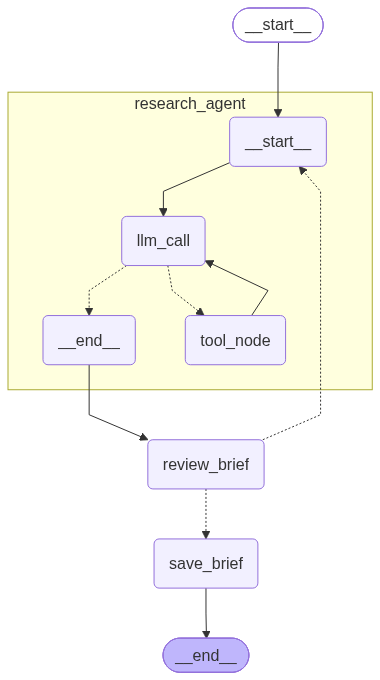

In [39]:
from IPython.display import Image

Image(graph.get_graph(xray=True).draw_mermaid_png())

## 5. Streaming the run

`stream_mode=["messages", "custom", "updates"]` with `subgraphs=True` yields `(namespace, mode, chunk)`:
- `namespace` is `()` for the outer graph and names the subgraph for steps inside `research_agent`;
- `messages`: `(token, metadata)` while the model writes; `metadata["langgraph_node"]` says which node (`llm_call`);
- `custom`: whatever a node sent with `get_stream_writer()` (here: the tool being called);
- `updates`: `{node: keys it returned}` after each node.

`agent_events()` turns that stream into a few simple events. `run()` prints them in the notebook; the chat UI of
section 8 shows **the same events** in a browser, so the scenarios and the UI share one piece of logic.

When the graph hits `interrupt()`, the stream **ends** with an `__interrupt__` update. You answer, then start a **new**
stream with `Command(resume=...)` on the same thread.

This is the classic tuple format. LangGraph 1.1+ also offers `version="v2"`, where every item is a dict with
`type`, `ns` and `data` ([Streaming](https://docs.langchain.com/oss/python/langgraph/streaming)).

In [40]:
def agent_events(inputs, config):
    """One run as events: ("token", text) · ("tool", status) · ("node", (name, keys)) · ("question" | "review", payload)."""
    for namespace, mode, chunk in graph.stream(inputs, config, stream_mode=["messages", "custom", "updates"], subgraphs=True):
        if mode == "messages":
            token, meta = chunk
            if meta.get("langgraph_node") == "llm_call" and token.text:  # text the model writes (not tool-call JSON)
                yield "token", token.text
        elif mode == "custom":
            yield "tool", chunk["status"]
        elif "__interrupt__" in chunk:
            if not namespace:  # the outer graph reports the pause; the stream ends here
                payload = chunk["__interrupt__"][0].value
                yield payload["type"], payload
        else:
            for node, update in chunk.items():
                yield "node", (("research_agent > " if namespace else "") + node, list(update or {}))


def run(inputs, config):
    """Stream one run in the notebook: tokens as they come, one log line per step. Returns the interrupt payload or None."""
    writing = False
    for kind, data in agent_events(inputs, config):
        if kind == "token":
            print(data, end="", flush=True)
            writing = True
            continue
        if writing:  # the model finished a block of text
            print()
            writing = False
        if kind == "tool":
            logger.info("  · %s", data)
        elif kind == "node":
            logger.info("[%s] %s", data[0], ", ".join(data[1]))
        else:
            return data
    return None

`answer()` turns an interrupt payload into the value for `Command(resume=...)`. Pass the replies as arguments to run a
scenario without typing, or leave them out to answer with `input()`.

In [41]:
def answer(payload, reply=None, decisions=None):
    """Show an interrupt payload and return the value for Command(resume=...)."""
    if payload["type"] == "question":
        reply = reply or input(f"? {payload['question']} > ")
        print(f"? {payload['question']} > {reply}")
        return reply
    print("--- review the draft above ---")  # run() already streamed it; payload["draft"] holds the same text
    print("citations:", payload["citations"])
    if decisions:
        decision = decisions.pop(0)
    else:
        choice = input("approve / edit / reject > ").strip().lower()
        decision = {"type": choice}
        if choice == "edit":
            decision["draft"] = input("new draft > ")
        elif choice == "reject":
            decision["feedback"] = input("feedback > ")
    logger.info("decision: %s", decision)
    return decision


def resume_until_done(payload, config, reply=None, decisions=None):
    decisions = list(decisions or [])
    while payload is not None:
        payload = run(Command(resume=answer(payload, reply, decisions)), config)
    final = graph.get_state(config).values
    logger.info("approval: %s | saved to: %s", final.get("approval"), final.get("output_path", "nothing"))


def run_to_end(request, config, reply=None, decisions=None):
    payload = run({"messages": [HumanMessage(request)]}, config)
    resume_until_done(payload, config, reply, decisions)

## 6. Scenarios

| Case | Request | Human | Expected |
|---|---|---|---|
| R01 | unclear: no reader given | answers the question, rejects once, then approves | asks once, rewrites after feedback, saves one file |
| R02 | pause, then "restart" | edits the draft | same thread continues; the file contains the edited text |
| R03 | clear request | approves | does **not** ask; saves |
| R04 | new `thread_id` | – | empty state |
| R05 | no source has the answer | approves | says the sources do not answer; no invented numbers |
| R06 | `recursion_limit = 4` | – | raises `GraphRecursionError` before a draft; nothing saved |

### R01 — unclear request: ask, reject once, approve
The `ask_user` progress line appears **twice**: on resume LangGraph runs the interrupted step again (every tool task of
that step), and this time `interrupt()` returns the answer. That is why side effects never go before `interrupt()`.

In [42]:
run_to_end(
    "Write a brief on electric car batteries.",
    thread("brief-R01"),
    reply="How long the batteries last, for people thinking about buying their first electric car.",
    decisions=[
        {"type": "reject", "feedback": "Add one practical tip to make the battery last longer."},
        {"type": "approve"},
    ],
)
print(Path("output/brief-R01.md").read_text())

INFO | [research_agent > llm_call] messages
INFO |   · ask_user {'question': 'What aspect of electric-car batteries should the brief cover, and who is the intended reader?'}
INFO |   · ask_user {'question': 'What aspect of electric-car batteries should the brief cover, and who is the intended reader?'}
INFO | [research_agent > tool_node] messages


? What aspect of electric-car batteries should the brief cover, and who is the intended reader? > How long the batteries last, for people thinking about buying their first electric car.


INFO | [research_agent > llm_call] messages
INFO |   · search_docs {'query': 'official study electric vehicle battery degradation lifespan years mileage battery health report'}
INFO |   · search_docs {'query': 'Geotab EV battery degradation study average annual degradation official 2024'}
INFO |   · search_docs {'query': 'DOE electric vehicle battery warranty 8 years 100000 miles battery lifespan'}
INFO | [research_agent > tool_node] messages
INFO | [research_agent > tool_node] messages
INFO | [research_agent > tool_node] messages
INFO | [research_agent > llm_call] messages
INFO |   · search_docs {'query': 'site:energy.gov electric vehicle battery warranty 8 years 100000 miles battery life'}
INFO |   · search_docs {'query': 'site:epa.gov electric vehicle battery warranty 8 years 100000 miles'}
INFO |   · search_docs {'query': 'NREL electric vehicle battery degradation lifespan study battery useful life'}
INFO | [research_agent > tool_node] messages
INFO | [research_agent > tool_node] m

## How long do electric-car batteries last?

**The battery usually lasts longer than many first-time buyers expect.** In a 2024 analysis of data from about 10,000 EVs, Geotab found average battery-capacity loss of 1.8% per year. The company says batteries at that rate could last 20 years or more, though this is an estimate—not a guarantee for every car. [Geotab](https://www.geotab.com/blog/ev-battery-study)

**Aging generally means less range, not sudden failure.** Battery capacity gradually declines, so a car may travel fewer miles on a charge as it gets older. The rate varies among models and vehicles; the 1.8% figure is an average. [Geotab](https://www.geotab.com/blog/ev-battery-study)

**Check the warranty for the specific car.** Many manufacturers offer battery warranties of 8 years or 100,000 miles, but coverage varies. Read the terms to see what capacity loss is covered and what conditions apply. The U.S. Department of Energy’s Alternative Fuels Data Center also notes that compr

INFO | [research_agent > llm_call] messages
INFO | [research_agent] messages
INFO | decision: {'type': 'reject', 'feedback': 'Add one practical tip to make the battery last longer.'}
INFO | [review_brief] approval, messages



--- review the draft above ---
citations: ['https://afdc.energy.gov/vehicles/electric-maintenance', 'https://www.energy.gov/bil/electric-drive-vehicle-battery-recycling-and-2nd-life-apps', 'https://www.geotab.com/blog/ev-battery-health', 'https://www.geotab.com/blog/ev-battery-study', 'https://www.geotab.com/press-release/ev-battery-health-degradation-fast-charging-study']


INFO | [research_agent > llm_call] messages
INFO |   · search_docs {'query': 'official EV battery longevity practical tip avoid frequent DC fast charging manufacturer guide battery care'}
INFO | [research_agent > tool_node] messages
INFO | [research_agent > llm_call] messages
INFO |   · search_docs {'query': 'site:energy.gov EV battery longevity charging 20% 80% battery care'}
INFO |   · search_docs {'query': 'site:afdc.energy.gov EV battery care charging habits battery life'}
INFO |   · search_docs {'query': 'Geotab battery degradation charging behaviors fast charging 2024 study avoid fast charging battery durability'}
INFO | [research_agent > tool_node] messages
INFO | [research_agent > tool_node] messages
INFO | [research_agent > tool_node] messages
INFO | [research_agent > llm_call] messages
INFO |   · read_doc {'url': 'https://www.geotab.com/blog/ev-battery-health', 'question': 'What practical charging behavior does the study say can reduce battery degradation, especially regardin

## How long do electric-car batteries last?

**The battery usually lasts longer than many first-time buyers expect.** Geotab’s 2024 analysis of data from about 10,000 EVs found average battery-capacity loss of 1.8% per year. The company says batteries at that rate could last 20 years or more, though this is an estimate—not a guarantee for every car. [Geotab](https://www.geotab.com/blog/ev-battery-study)

**Aging generally means less range, not sudden failure.** Capacity declines over time, so an older car may travel fewer miles on a charge. The rate varies among models and vehicles; 1.8% is an average. [Geotab](https://www.geotab.com/blog/ev-battery-study)

**A practical tip:** When convenient, use slower Level 2 charging instead of frequently relying on DC fast charging. Geotab’s analysis found that more frequent DC fast charging was associated with faster capacity loss on average. [Geotab](https://www.geotab.com/blog/ev-battery-health)

**Check the warranty for the specific car.** Ma

INFO | [research_agent > llm_call] messages
INFO | [research_agent] messages, approval
INFO | decision: {'type': 'approve'}
INFO | [review_brief] approval
INFO | [save_brief] output_path
INFO | approval: approved | saved to: output/brief-R01.md



--- review the draft above ---
citations: ['https://afdc.energy.gov/vehicles/electric-maintenance', 'https://www.energy.gov/bil/electric-drive-vehicle-battery-recycling-and-2nd-life-apps', 'https://www.geotab.com/blog/ev-battery-health', 'https://www.geotab.com/blog/ev-battery-study', 'https://www.geotab.com/press-release/ev-battery-health-degradation-fast-charging-study']
## How long do electric-car batteries last?

**The battery usually lasts longer than many first-time buyers expect.** Geotab’s 2024 analysis of data from about 10,000 EVs found average battery-capacity loss of 1.8% per year. The company says batteries at that rate could last 20 years or more, though this is an estimate—not a guarantee for every car. [Geotab](https://www.geotab.com/blog/ev-battery-study)

**Aging generally means less range, not sudden failure.** Capacity declines over time, so an older car may travel fewer miles on a charge. The rate varies among models and vehicles; 1.8% is an average. [Geotab](http

### R02 — inspect the state and continue after a restart
`get_state(config)` returns the latest checkpoint of a thread: its values and the next node to run.

1. Start thread `brief-R02` and stop at the first pause (do not answer).
2. Simulate a restart: close the connection and build a **new** graph on the same `checkpoints.sqlite`.
   (Better: restart the kernel, run sections 0–5, then the next cell.)
3. Read the pending interrupt from the snapshot and continue the same thread.

With `InMemorySaver` the state would be gone after the restart.

In [44]:
config2 = thread("brief-R02")
paused = run({"messages": [HumanMessage("Write a brief about remote work.")]}, config2)
logger.info("paused with: %s", paused)

conn.close()  # "restart"
conn = sqlite3.connect("checkpoints.sqlite", check_same_thread=False)
graph = build_graph(SqliteSaver(conn))

INFO | [research_agent > llm_call] messages
INFO |   · ask_user {'question': 'What aspect of remote work should the brief cover, and who is the intended reader?'}
INFO | paused with: {'type': 'question', 'question': 'What aspect of remote work should the brief cover, and who is the intended reader?'}


In [45]:
snapshot = graph.get_state(config2)
logger.info("next node: %s", snapshot.next)
logger.info("pending interrupt: %s", snapshot.interrupts[0].value)

resume_until_done(
    snapshot.interrupts[0].value,
    config2,
    reply="Effects of remote work on productivity, for managers of small software teams.",
    decisions=[{"type": "edit", "draft": "Remote work: keep a weekly team meeting and clear written goals."}],
)
print(Path("output/brief-R02.md").read_text())

INFO | next node: ('research_agent',)
INFO | pending interrupt: {'type': 'question', 'question': 'What aspect of remote work should the brief cover, and who is the intended reader?'}
INFO |   · ask_user {'question': 'What aspect of remote work should the brief cover, and who is the intended reader?'}
INFO | [research_agent > tool_node] messages


? What aspect of remote work should the brief cover, and who is the intended reader? > Effects of remote work on productivity, for managers of small software teams.


INFO | [research_agent > llm_call] messages
INFO |   · search_docs {'query': 'remote work productivity randomized trial software engineers productivity Nature 2024 hybrid work'}
INFO |   · search_docs {'query': 'remote work productivity study software developers GitLab Microsoft research productivity official'}
INFO |   · search_docs {'query': 'remote work productivity evidence managers small teams research productivity remote work official report'}
INFO | [research_agent > tool_node] messages
INFO | [research_agent > tool_node] messages
INFO | [research_agent > tool_node] messages
INFO | [research_agent > llm_call] messages
INFO |   · search_docs {'query': 'Nature 2024 hybrid working from home randomized control trial productivity performance Trip.com study'}
INFO |   · search_docs {'query': 'remote work productivity randomized trial call center Ctrip study NBER working paper'}
INFO |   · search_docs {'query': 'GitHub remote work productivity developer study hybrid productivity resear

### Remote work and productivity: a brief for small software teams

Remote work does not automatically raise or lower productivity. In a six-month randomized trial at a large Chinese technology company, a two-day-per-week work-from-home schedule did not change performance grades or promotions; among computer engineers, it also had no measurable effect on lines of code written. The hybrid schedule did, however, reduce quit rates by one-third and improve job satisfaction. [Study](https://pmc.ncbi.nlm.nih.gov/articles/PMC11208135)

A separate randomized experiment at a Chinese travel company found that call-center workers’ productivity rose 13% when working from home, with no measurable decline in call quality. But this was a different kind of work, so the result should not be assumed to apply to software development. [NBER summary](https://www.nber.org/digest/sep13/evidence-chinese-experiment-working-home)

**Practical takeaway:** Treat remote-work arrangements as a team-design choice, n

INFO | [research_agent > llm_call] messages
INFO | [research_agent] messages
INFO | decision: {'type': 'edit', 'draft': 'Remote work: keep a weekly team meeting and clear written goals.'}
INFO | [review_brief] approval, messages
INFO | [save_brief] output_path
INFO | approval: edited | saved to: output/brief-R02.md



--- review the draft above ---
citations: ['https://pmc.ncbi.nlm.nih.gov/articles/PMC11208135', 'https://siepr.stanford.edu/news/hybrid-work-win-win-win-companies-workers-study-finds', 'https://www.nber.org/digest/sep13/evidence-chinese-experiment-working-home']
Remote work: keep a weekly team meeting and clear written goals.

## Sources read
- https://pmc.ncbi.nlm.nih.gov/articles/PMC11208135
- https://siepr.stanford.edu/news/hybrid-work-win-win-win-companies-workers-study-finds
- https://www.nber.org/digest/sep13/evidence-chinese-experiment-working-home



### R03 — a clear request: the agent should not ask

In [46]:
# run_to_end(
#     "Write a brief for city council members on urban heat islands: causes and two proven ways to reduce them.",
#     thread("brief-R03"),
#     reply="City council members.",  # used only if the agent asks
#     decisions=[{"type": "approve"}],
# )

### R04 — a new `thread_id` starts clean: no messages, no draft from the other threads

In [47]:
# print(graph.get_state(thread("brief-new")).values)

### R05 — a request the docs do not cover

In [48]:
# run_to_end(
#     "Write a brief for a café owner with the exact number of cups of coffee sold worldwide yesterday.",
#     thread("brief-R05"),
#     reply="A café owner who wants yesterday's exact worldwide number.",
#     decisions=[{"type": "approve"}],
# )

### R06 — the step limit
With `recursion_limit = 4` the research loop cannot finish (search, read, write needs more steps), so LangGraph raises
`GraphRecursionError`, exactly as `create_agent` would. The review never starts and nothing is saved.

In [49]:
# from langgraph.errors import GraphRecursionError

# config6 = thread("brief-R06", recursion_limit=4)
# try:
#     run_to_end("Write a brief for UK homeowners comparing heat pumps and gas boilers on running cost.", config6, reply="UK homeowners.")
# except GraphRecursionError as error:
#     logger.warning("GraphRecursionError: %s", str(error).splitlines()[0])
# logger.info("saved to: %s", graph.get_state(config6).values.get("output_path", "nothing"))

### Your turn: talk to the agent
Without `reply` and `decisions`, `answer()` asks **you** with `input()`: answer the agent's question, then type
`approve`, `edit` or `reject`. Uncomment the line, change the request or the thread id, and run it.

In [ ]:
# run_to_end("Write a brief on electric car batteries.", thread("01"))

## 7. The same agent with `create_agent` and middleware

`create_agent` gives you the loop; middleware adds control around model and tool calls:
- `HumanInTheLoopMiddleware` pauses **before** a chosen tool runs; you approve, edit, reject or respond.
- `ToolRetryMiddleware` retries failed tool calls; `ToolCallLimitMiddleware` caps tool calls per run.

Here saving is a tool (`save_brief`), so the approval happens on that tool call.

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware, ToolCallLimitMiddleware, ToolRetryMiddleware
from langgraph.checkpoint.memory import InMemorySaver


@tool
def save_brief(content: str) -> str:
    """Save the finished brief (markdown, with its sources) to a file. Returns the file path."""
    OUTPUT_DIR.mkdir(exist_ok=True)
    path = OUTPUT_DIR / "brief-agent.md"
    path.write_text(content, encoding="utf-8")
    return str(path)


agent = create_agent(
    model=model,
    tools=[search_docs, read_doc, save_brief],
    system_prompt=SYSTEM_PROMPT + " Write for a general audience. When the brief is ready, save it with save_brief.",
    middleware=[
        HumanInTheLoopMiddleware(interrupt_on={"save_brief": True}),
        ToolRetryMiddleware(max_retries=2),
        ToolCallLimitMiddleware(run_limit=8),
    ],
    checkpointer=InMemorySaver(),
)


def run_agent(request, config, decisions):
    """Invoke the agent; answer each pending save_brief call with the next decision."""
    out = agent.invoke({"messages": [HumanMessage(request)]}, config)
    while "__interrupt__" in out:
        call = out["__interrupt__"][0].value["action_requests"][0]
        logger.info("waiting for approval: %s", call["name"])
        print(call["args"]["content"])
        decision = decisions.pop(0)
        logger.info("decision: %s", decision)
        out = agent.invoke(Command(resume={"decisions": [decision]}), config)
    logger.info("last tool result: %s", next(m.content for m in reversed(out["messages"]) if isinstance(m, ToolMessage)))
    return out

Reject the first save with a message, then approve the revised one. Only the approved call writes the file:

In [ ]:
Path("output/brief-agent.md").unlink(missing_ok=True)
out = run_agent(
    "Write a brief on how heat pumps work.",
    {"configurable": {"thread_id": "agent-R01"}, "recursion_limit": 20},
    decisions=[{"type": "reject", "message": "Add one sentence on when a heat pump is not a good choice."}, {"type": "approve"}],
)
print(Path("output/brief-agent.md").read_text())

INFO | waiting for approval: save_brief


INFO | decision: {'type': 'reject', 'message': 'Add one sentence on when a heat pump is not a good choice.'}


## How heat pumps work

A heat pump moves heat rather than creating it by burning fuel. It takes heat from a source—commonly outdoor air, the ground, or water—and transfers it into a building. In summer, many systems can reverse the process and carry indoor heat outside, providing cooling. [International Energy Agency](https://www.iea.org/reports/the-future-of-heat-pumps/how-a-heat-pump-works) · [Cornell Cooperative Extension of Tompkins County](https://energy.ccetompkins.org/energy-solutions/heat-pumps)

Inside the system, a refrigerant circulates in a closed loop through four main parts. In the **evaporator**, it absorbs heat and evaporates into a gas. The **compressor** squeezes the gas, raising its pressure and temperature. In the **condenser**, the hot refrigerant releases heat to the building and turns back into a liquid. An **expansion valve** lowers its pressure and temperature so it can absorb heat again; the cycle repeats. [Heat Pumping Technologies](https://heatpumpingtechno

INFO | waiting for approval: save_brief


INFO | decision: {'type': 'approve'}


## How heat pumps work

A heat pump moves heat rather than creating it by burning fuel. It takes heat from a source—commonly outdoor air, the ground, or water—and transfers it into a building. In summer, many systems can reverse the process and carry indoor heat outside, providing cooling. [International Energy Agency](https://www.iea.org/reports/the-future-of-heat-pumps/how-a-heat-pump-works) · [Cornell Cooperative Extension of Tompkins County](https://energy.ccetompkins.org/energy-solutions/heat-pumps)

Inside the system, a refrigerant circulates in a closed loop through four main parts. In the **evaporator**, it absorbs heat and evaporates into a gas. The **compressor** squeezes the gas, raising its pressure and temperature. In the **condenser**, the hot refrigerant releases heat to the building and turns back into a liquid. An **expansion valve** lowers its pressure and temperature so it can absorb heat again; the cycle repeats. [Heat Pumping Technologies](https://heatpumpingtechno

INFO | last tool result: output/brief-agent.md


## How heat pumps work

A heat pump moves heat rather than creating it by burning fuel. It takes heat from a source—commonly outdoor air, the ground, or water—and transfers it into a building. In summer, many systems can reverse the process and carry indoor heat outside, providing cooling. [International Energy Agency](https://www.iea.org/reports/the-future-of-heat-pumps/how-a-heat-pump-works) · [Cornell Cooperative Extension of Tompkins County](https://energy.ccetompkins.org/energy-solutions/heat-pumps)

Inside the system, a refrigerant circulates in a closed loop through four main parts. In the **evaporator**, it absorbs heat and evaporates into a gas. The **compressor** squeezes the gas, raising its pressure and temperature. In the **condenser**, the hot refrigerant releases heat to the building and turns back into a liquid. An **expansion valve** lowers its pressure and temperature so it can absorb heat again; the cycle repeats. [Heat Pumping Technologies](https://heatpumpingtechno

## 8. Try it in a chat UI (Gradio)

The same graph behind a chat window, so you can hold a real conversation with the agent. No new agent logic: the UI only
**displays** what the functions above already produce.

| In the UI | Comes from |
|---|---|
| everything that streams | `agent_events()` of section 5, the same events `run()` prints in the scenarios |
| tokens appearing as the agent writes | `stream_mode="messages"`, tokens of the `llm_call` node |
| "Tool call" blocks (search, read, ask) | `get_stream_writer()` events of `tool_node` (`stream_mode="custom"`) |
| the agent's question, then your answer | `ask_user` → `interrupt()`; your reply → `Command(resume=answer)` |
| Review panel: Approve / Edit & save / Reject | `review_brief` → `interrupt(payload)`; buttons → `Command(resume={"type": ...})` |
| Thread ID (new on every page load), Load thread | `thread(thread_id)` config + `SqliteSaver`: reload any thread, even `brief-R01` |
| State panel | `graph.get_state(config)`: next node, approval, saved file, pages read (`read_sources`) |

In [ ]:
import uuid

import gradio as gr


def new_thread_id() -> str:
    return f"ui-{uuid.uuid4().hex[:8]}"


def pending(thread_id: str):
    """The interrupt payload the thread is waiting on (question or review), or None."""
    snapshot = graph.get_state(thread(thread_id))
    return snapshot.interrupts[0].value if snapshot.interrupts else None


def state_panel(thread_id: str) -> str:
    snapshot = graph.get_state(thread(thread_id))
    values = snapshot.values
    pages = read_sources(values.get("messages", []))
    lines = [f"**Thread** `{thread_id}`", f"**Next node** {', '.join(snapshot.next) or '(done)'}",
             f"**Approval** {values.get('approval', '-')}", f"**Saved file** {values.get('output_path', '-')}",
             f"**Pages read** ({len(pages)})"] + [f"- {url}" for url in pages]
    return "\n\n".join(lines[:5]) + "\n" + "\n".join(lines[5:])


def review_view(thread_id: str):
    """Show the review panel (draft + citations) only while review_brief is waiting."""
    payload = pending(thread_id)
    if payload and payload["type"] == "review":
        cites = "\n".join(f"- {url}" for url in payload["citations"]) or "- none"
        return gr.update(visible=True), payload["draft"], f"**Citations**\n{cites}"
    return gr.update(visible=False), "", ""

`stream_to_chat` is `run()` from section 5 for a chat window: it reads the same `agent_events()` and turns each event into a chat message.

In [ ]:
KEEP = gr.update()  # leave a component unchanged


def stream_to_chat(inputs, thread_id: str, chat: list):
    """run() for a chat window: the same agent_events, shown as chat messages. Yields UI updates."""
    chat = chat + [{"role": "assistant", "content": "", "metadata": {"title": "Working…", "status": "pending"}}]
    writing = None  # index of the message that receives the tokens of the current model turn
    for kind, data in agent_events(inputs, thread(thread_id)):
        if kind == "token":
            if writing is None:
                chat.append({"role": "assistant", "content": ""})
                writing = len(chat) - 1
            chat[writing]["content"] += data
        else:
            writing = None
        if kind == "tool":
            chat.append({"role": "assistant", "content": data, "metadata": {"title": "Tool call", "status": "done"}})
        elif kind == "question":
            chat.append({"role": "assistant", "content": f"**Question:** {data['question']}\n\n_Answer in the message box._"})
        elif kind == "review":
            chat.append({"role": "assistant", "content": "**Draft ready for review** → use the Review panel."})
        elif kind == "node":
            logger.info("[%s] %s", data[0], ", ".join(data[1]))
            if data[0] == "save_brief":
                chat.append({"role": "assistant", "content": f"Saved to `{graph.get_state(thread(thread_id)).values['output_path']}`."})
        yield chat, KEEP, KEEP, KEEP, KEEP  # while streaming, only the chat changes
    chat = [m for m in chat if (m.get("metadata") or {}).get("title") != "Working…"]
    yield chat, *review_view(thread_id), state_panel(thread_id)

Event handlers: each one turns a UI action into the graph input you already know.

In [ ]:
def on_send(text: str, thread_id: str, chat: list):
    payload = pending(thread_id)
    if payload and payload["type"] == "review":
        yield chat + [{"role": "assistant", "content": "Use the Review panel to approve, edit or reject the draft."}], \
              *review_view(thread_id), state_panel(thread_id)
        return
    inputs = Command(resume=text) if payload else {"messages": [HumanMessage(text)]}  # answer or new request
    yield from stream_to_chat(inputs, thread_id, chat + [{"role": "user", "content": text}])


def on_approve(thread_id: str, chat: list):
    yield from stream_to_chat(Command(resume={"type": "approve"}), thread_id, chat + [{"role": "user", "content": "Approve"}])


def on_edit(draft: str, thread_id: str, chat: list):
    yield from stream_to_chat(Command(resume={"type": "edit", "draft": draft}), thread_id,
                              chat + [{"role": "user", "content": "Edit & save"}])


def on_reject(feedback: str, thread_id: str, chat: list):
    yield from stream_to_chat(Command(resume={"type": "reject", "feedback": feedback}), thread_id,
                              chat + [{"role": "user", "content": f"Reject: {feedback}"}])


def on_load(thread_id: str):
    """Rebuild the chat of a saved thread from its checkpoint (persistence)."""
    chat = []
    for m in graph.get_state(thread(thread_id)).values.get("messages", []):
        if m.type == "human":
            chat.append({"role": "user", "content": m.text})
        elif m.type == "ai" and m.tool_calls:
            chat += [{"role": "assistant", "content": f"{c['name']} {c['args']}", "metadata": {"title": "Tool call", "status": "done"}}
                     for c in m.tool_calls]
        elif m.type == "ai" and m.text:
            chat.append({"role": "assistant", "content": m.text})
    payload = pending(thread_id)
    if payload and payload["type"] == "question":
        chat.append({"role": "assistant", "content": f"**Question:** {payload['question']}"})
    return chat, *review_view(thread_id), state_panel(thread_id)

In [ ]:
with gr.Blocks(title="Research Brief Agent") as demo:
    gr.Markdown("## Research Brief Agent\nAsk for a brief. The agent may ask you a question, then waits for your review before saving.")
    with gr.Row():
        with gr.Column(scale=3):
            chatbot = gr.Chatbot(height=560, label="Conversation")
            message = gr.Textbox(label="Message", placeholder="e.g. Write a brief on electric car batteries.", submit_btn=True)
        with gr.Column(scale=2):
            thread_box = gr.Textbox(label="Thread ID (new for every visit; type an existing one and press Load)")
            with gr.Row():
                new_btn = gr.Button("New thread")
                load_btn = gr.Button("Load thread")
            with gr.Group(visible=False) as review_panel:
                draft_box = gr.Textbox(label="Draft (you can edit it)", lines=12)
                citations_md = gr.Markdown()
                feedback_box = gr.Textbox(label="Feedback (for Reject)")
                with gr.Row():
                    approve_btn = gr.Button("Approve", variant="primary")
                    edit_btn = gr.Button("Edit & save")
                    reject_btn = gr.Button("Reject", variant="stop")
            state_md = gr.Markdown()

    outputs = [chatbot, review_panel, draft_box, citations_md, state_md]
    message.submit(on_send, [message, thread_box, chatbot], outputs).then(lambda: "", None, message)
    approve_btn.click(on_approve, [thread_box, chatbot], outputs)
    edit_btn.click(on_edit, [draft_box, thread_box, chatbot], outputs)
    reject_btn.click(on_reject, [feedback_box, thread_box, chatbot], outputs)
    new_btn.click(lambda: (new_thread_id(), [], gr.update(visible=False), "", "", ""), None,
                  [thread_box, chatbot, review_panel, draft_box, citations_md, state_md])
    load_btn.click(on_load, thread_box, outputs)
    demo.load(new_thread_id, None, thread_box)  # every page load (refresh, new user) starts a new thread

Uncomment the next cell to start the UI, then open the address it prints (http://127.0.0.1:7860) in your browser.
Try: *"Write a brief on electric car batteries."* → answer the question → Reject with feedback → Approve.
Then press **New thread**, or type `brief-R01` and press **Load thread** to see a thread from section 6.
Stop it with `demo.close()`.

In [ ]:
# demo.launch(prevent_thread_lock=True)